
# Telco Customer Churn Prediction

## 1. Business Problem and Project Objective

Telecommunications companies need to understand why customers leave their services and identify customers who may be at elevated risk of churn. Customer churn can affect customer retention, recurring revenue, and long-term business performance.

This project uses a telecommunications customer dataset to develop and compare machine-learning classification models that predict whether a customer has churned (`Yes` or `No`).

The project will investigate customer demographics, tenure, subscribed services, contract types, billing information, and payment methods as potential predictors of churn.

### Business KPI

The primary business KPI is **early-tenure revenue-weighted churn exposure**, calculated for customers whose recorded tenure is six months or less:

Early-tenure churn exposure (%) =

(Sum of monthly charges associated with churned customers in the early-tenure cohort / Sum of monthly charges for all customers in the early-tenure cohort) × 100

The KPI is descriptive of the recorded dataset. It should not be interpreted as a verified percentage of revenue permanently lost or as a prospective six-month churn rate.

### Modelling Objective

The modelling objective is to compare Logistic Regression and Random Forest classification models using an appropriate train/test evaluation strategy. Model performance will be assessed using recall, precision, F1-score, ROC-AUC, and the confusion matrix, alongside accuracy.

The analysis will also investigate data quality, potential data leakage, feature suitability, and the business implications of the findings.


In [112]:

# Core libraries for data handling and analysis
import os
from pathlib import Path

import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
RANDOM_STATE = 42

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully.
Pandas version: 3.0.3
NumPy version: 2.4.4


In [113]:

# Path to the assessment folder
PROJECT_DIR = Path(
    "/Users/ifadha/Documents/MSc in Datascience and AI/Y2/Sem1/ML and AI /Assessment 1 Portfolio"
)

# Path to the Telco dataset
DATA_PATH = PROJECT_DIR / "Datasets" / "telco_churn_with_all_feedback.csv"

# Verify the path before attempting to read the file
print("Dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Check the folder and filename, "
        "then update DATA_PATH to the correct location."
    )

# Load the original dataset
telco_raw = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully.")
print("Rows:", telco_raw.shape[0])
print("Columns:", telco_raw.shape[1])


Dataset path: /Users/ifadha/Documents/MSc in Datascience and AI/Y2/Sem1/ML and AI /Assessment 1 Portfolio/Datasets/telco_churn_with_all_feedback.csv
File exists: True

Dataset loaded successfully.
Rows: 7043
Columns: 23


In [114]:

# Preview the first five records
display(telco_raw.head())

# Confirm the dataset dimensions
print("Dataset shape:", telco_raw.shape)

# Inspect column names and data types
print("\nDataset information:")
telco_raw.info()

# Summary statistics for numeric columns
print("\nNumeric summary:")
display(telco_raw.describe())

# Summary statistics for categorical/text columns
print("\nCategorical summary:")
display(telco_raw.describe(include="object").T)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,PromptInput,CustomerFeedback
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,Write a realistic customer feedback based on this profile:\nChurn: No\nTenure: 1 months\nContrac...,"I have been using the DSL internet service from this provider for the past month and so far, I a..."
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No,Write a realistic customer feedback based on this profile:\nChurn: No\nTenure: 34 months\nContra...,I have been a customer with this company for over two and a half years now and I have been very ...
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Write a realistic customer feedback based on this profile:\nChurn: Yes\nTenure: 2 months\nContra...,I recently signed up for DSL internet service with this provider two months ago on a month-to-mo...
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Write a realistic customer feedback based on this profile:\nChurn: No\nTenure: 45 months\nContra...,I have been a loyal customer with this company for 45 months now and I am very satisfied with th...
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Write a realistic customer feedback based on this profile:\nChurn: Yes\nTenure: 2 months\nContra...,I recently switched to this fiber optic internet service provider two months ago on a month-to-m...


Dataset shape: (7043, 23)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  Paper

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Categorical summary:


/var/folders/fp/qjkl05zd67g776y0kbfpn6sw0000gn/T/ipykernel_57621/703573654.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(telco_raw.describe(include="object").T)


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


Target values:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Target distribution (%):


,Percentage
Churn,
No,73.46
Yes,26.54


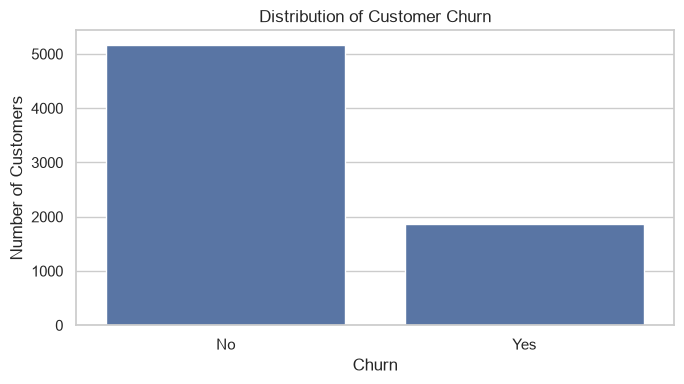

In [115]:

# Check whether the target column exists
assert "Churn" in telco_raw.columns, "Target column 'Churn' was not found."

# Inspect target labels and counts
print("Target values:")
display(telco_raw["Churn"].value_counts(dropna=False))

print("\nTarget distribution (%):")
display(
    (
        telco_raw["Churn"]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
        .rename("Percentage")
        .to_frame()
    )
)

# Visualise the target distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=telco_raw, x="Churn")
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()



## 2. Data Preparation and Quality Assessment

Before developing the classification models, the dataset must be checked for data-quality issues that could affect reliability and reproducibility.

The initial inspection identified 7,043 customer records and 23 attributes. The target variable, `Churn`, contains two classes: `No` (73.46%) and `Yes` (26.54%).

The following checks will investigate duplicate records, missing values, blank strings, unexpected categorical values, and data types. The results will inform the cleaning and preprocessing decisions made before model training.


In [116]:

# Check for fully duplicated rows
duplicate_rows = telco_raw.duplicated().sum()

# Check for duplicate customer identifiers
duplicate_customer_ids = telco_raw["customerID"].duplicated().sum()

print("Total rows:", len(telco_raw))
print("Fully duplicated rows:", duplicate_rows)
print("Duplicate customer IDs:", duplicate_customer_ids)


Total rows: 7043
Fully duplicated rows: 0
Duplicate customer IDs: 0


In [117]:

# Count conventional missing values
missing_values = telco_raw.isna().sum()

# Count empty or whitespace-only strings in text columns
blank_strings = pd.Series({
    col: telco_raw[col]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    for col in telco_raw.select_dtypes(include=["str", "object"]).columns
})

quality_summary = pd.DataFrame({
    "Missing values": missing_values,
    "Blank strings": blank_strings.reindex(
        missing_values.index, fill_value=0
    )
})

quality_summary["Total issues"] = (
    quality_summary["Missing values"] +
    quality_summary["Blank strings"]
)

display(
    quality_summary.sort_values(
        "Total issues", ascending=False
    )
)

print(
    "\nColumns with missing values:",
    int((quality_summary["Missing values"] > 0).sum())
)

print(
    "Columns with blank strings:",
    int((quality_summary["Blank strings"] > 0).sum())
)


,Missing values,Blank strings,Total issues
TotalCharges,0,11,11
customerID,0,0,0
TechSupport,0,0,0
PromptInput,0,0,0
Churn,0,0,0
MonthlyCharges,0,0,0
PaymentMethod,0,0,0
PaperlessBilling,0,0,0
Contract,0,0,0
StreamingMovies,0,0,0



Columns with missing values: 0
Columns with blank strings: 1


In [118]:

# Expected categories based on the dataset's intended schema
expected_categories = {
    "gender": {"Female", "Male"},
    "Partner": {"Yes", "No"},
    "Dependents": {"Yes", "No"},
    "PhoneService": {"Yes", "No"},
    "MultipleLines": {"Yes", "No", "No phone service"},
    "InternetService": {"DSL", "Fiber optic", "No"},
    "OnlineSecurity": {"Yes", "No", "No internet service"},
    "OnlineBackup": {"Yes", "No", "No internet service"},
    "DeviceProtection": {"Yes", "No", "No internet service"},
    "TechSupport": {"Yes", "No", "No internet service"},
    "StreamingTV": {"Yes", "No", "No internet service"},
    "StreamingMovies": {"Yes", "No", "No internet service"},
    "Contract": {"Month-to-month", "One year", "Two year"},
    "PaperlessBilling": {"Yes", "No"},
    "PaymentMethod": {
        "Electronic check",
        "Mailed check",
        "Bank transfer (automatic)",
        "Credit card (automatic)"
    },
    "Churn": {"Yes", "No"}
}

for col, expected in expected_categories.items():
    observed = set(
        telco_raw[col].dropna().astype("string").str.strip().unique()
    )

    unexpected = observed - expected

    print(f"\n{col}")
    print("Observed categories:", sorted(observed))
    print("Unexpected categories:", sorted(unexpected))



gender
Observed categories: ['Female', 'Male']
Unexpected categories: []

Partner
Observed categories: ['No', 'Yes']
Unexpected categories: []

Dependents
Observed categories: ['No', 'Yes']
Unexpected categories: []

PhoneService
Observed categories: ['No', 'Yes']
Unexpected categories: []

MultipleLines
Observed categories: ['No', 'No phone service', 'Yes']
Unexpected categories: []

InternetService
Observed categories: ['DSL', 'Fiber optic', 'No']
Unexpected categories: []

OnlineSecurity
Observed categories: ['No', 'No internet service', 'Yes']
Unexpected categories: []

OnlineBackup
Observed categories: ['No', 'No internet service', 'Yes']
Unexpected categories: []

DeviceProtection
Observed categories: ['No', 'No internet service', 'Yes']
Unexpected categories: []

TechSupport
Observed categories: ['No', 'No internet service', 'Yes']
Unexpected categories: []

StreamingTV
Observed categories: ['No', 'No internet service', 'Yes']
Unexpected categories: []

StreamingMovies
Observed

In [119]:

# Preserve the original TotalCharges column
total_charges_original = telco_raw["TotalCharges"].copy()

# Inspect values that are blank or whitespace-only
total_charges_stripped = (
    total_charges_original.astype("string").str.strip()
)

blank_total_charges = total_charges_stripped.eq("")

print("Blank TotalCharges entries:", int(blank_total_charges.sum()))

print("\nExamples of blank entries:")
display(
    telco_raw.loc[
        blank_total_charges,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ].head(15)
)

# Attempt numeric conversion without changing the original dataset
total_charges_numeric = pd.to_numeric(
    total_charges_stripped,
    errors="coerce"
)

invalid_total_charges = (
    total_charges_numeric.isna() &
    total_charges_stripped.ne("")
)

print(
    "\nNon-blank values that cannot be converted:",
    int(invalid_total_charges.sum())
)

print(
    "Successfully converted numeric values:",
    int(total_charges_numeric.notna().sum())
)

print("\nConverted numeric summary:")
display(total_charges_numeric.describe())


Blank TotalCharges entries: 11

Examples of blank entries:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
1218,2923-ARZLG,0,19.70,,No
2670,4075-WKNIU,0,73.35,,No
2754,2775-SEFEE,0,61.90,,No
3296,3115-CZMZD,0,20.25,,No
3479,5709-LVOEQ,0,80.85,,No
3625,4367-NUYAO,0,25.75,,No
3883,1371-DWPAZ,0,56.05,,No
5874,7644-OMVMY,0,19.85,,No
6369,3213-VVOLG,0,25.35,,No



Non-blank values that cannot be converted: 0
Successfully converted numeric values: 7032

Converted numeric summary:


count         7032.0
mean     2283.300441
std      2266.771362
min             18.8
25%           401.45
50%         1397.475
75%        3794.7375
max           8684.8
Name: TotalCharges, dtype: Float64

In [120]:

# Validate target labels
print("Churn labels:")
display(telco_raw["Churn"].value_counts(dropna=False))

valid_churn_labels = {"Yes", "No"}
observed_churn_labels = set(telco_raw["Churn"].dropna().unique())

print(
    "\nAll target labels valid:",
    observed_churn_labels.issubset(valid_churn_labels)
)

# Check numeric ranges and unusual values
numeric_checks = {
    "SeniorCitizen": (0, 1),
    "tenure": (0, 72),
    "MonthlyCharges": (0, float("inf"))
}

for col, (minimum, maximum) in numeric_checks.items():
    values = pd.to_numeric(telco_raw[col], errors="coerce")

    invalid = (
        values.isna() |
        (values < minimum) |
        (values > maximum)
    )

    print(f"\n{col}")
    print("Minimum:", values.min())
    print("Maximum:", values.max())
    print("Invalid values:", int(invalid.sum()))


Churn labels:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


All target labels valid: True

SeniorCitizen
Minimum: 0
Maximum: 1
Invalid values: 0

tenure
Minimum: 0
Maximum: 72
Invalid values: 0

MonthlyCharges
Minimum: 18.25
Maximum: 118.75
Invalid values: 0


## 3. Data Cleaning and Validation

The quality assessment found no duplicate records, duplicate customer identifiers, or unexpected values in the checked categorical columns. However, `TotalCharges` contains 11 blank strings that must be handled explicitly.

A cleaned copy of the dataset will be created while preserving the original raw DataFrame. Text values will be stripped of surrounding whitespace, and `TotalCharges` will be converted to a numeric data type. Blank values will become missing values rather than being arbitrarily replaced.

The 11 affected records will be retained. `TotalCharges` will be excluded from the initial model features, while its missingness and relationship with customer tenure will be documented. The generated text columns `PromptInput` and `CustomerFeedback`, along with the customer identifier, will also be excluded from the initial predictive feature set to reduce the risk of target leakage.

In [121]:
# Create a cleaned copy; preserve telco_raw unchanged
telco = telco_raw.copy()

# Remove surrounding whitespace from string columns
string_columns = telco.select_dtypes(
    include=["str", "object"]
).columns

for col in string_columns:
    telco[col] = telco[col].astype("string").str.strip()

# Convert TotalCharges to numeric.
# Blank strings become missing values.
telco["TotalCharges"] = pd.to_numeric(
    telco["TotalCharges"].replace("", pd.NA),
    errors="coerce"
)

# Create a binary target for later classification
telco["ChurnFlag"] = telco["Churn"].map({
    "No": 0,
    "Yes": 1
}).astype("int8")

print("Cleaned dataset created successfully.")
print("Original dataset shape:", telco_raw.shape)
print("Cleaned dataset shape:", telco.shape)
print("TotalCharges data type:", telco["TotalCharges"].dtype)
print("Missing TotalCharges:", telco["TotalCharges"].isna().sum())
print("Missing values in ChurnFlag:", telco["ChurnFlag"].isna().sum())

Cleaned dataset created successfully.
Original dataset shape: (7043, 23)
Cleaned dataset shape: (7043, 24)
TotalCharges data type: Float64
Missing TotalCharges: 11
Missing values in ChurnFlag: 0


In [122]:
# Confirm the original raw data has not been modified
print(
    "Raw dataset unchanged:",
    telco_raw["TotalCharges"].equals(total_charges_original)
)

# Confirm no duplicate rows or customer identifiers were introduced
print("Duplicate rows after cleaning:", telco.duplicated().sum())
print("Duplicate customer IDs after cleaning:",
      telco["customerID"].duplicated().sum())

# Inspect records with missing TotalCharges
missing_total = telco.loc[
    telco["TotalCharges"].isna(),
    ["customerID", "tenure", "MonthlyCharges",
     "TotalCharges", "Churn", "ChurnFlag"]
]

print("\nRecords with missing TotalCharges:")
display(missing_total)

print("\nTenure values among records with missing TotalCharges:")
display(missing_total["tenure"].value_counts(dropna=False))

print("\nChurn labels among records with missing TotalCharges:")
display(missing_total["Churn"].value_counts(dropna=False))

# Confirm target mapping
print("\nChurn and binary target cross-check:")
display(
    telco[["Churn", "ChurnFlag"]]
    .drop_duplicates()
    .sort_values("ChurnFlag")
)

# Check whether any target labels failed to map
assert telco["ChurnFlag"].notna().all()
assert set(telco["ChurnFlag"].unique()) == {0, 1}
assert telco["customerID"].is_unique

print("\nAll cleaning validation assertions passed.")

Raw dataset unchanged: True
Duplicate rows after cleaning: 0
Duplicate customer IDs after cleaning: 0

Records with missing TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn,ChurnFlag
488,4472-LVYGI,0,52.55,<NA>,No,0
1218,2923-ARZLG,0,19.70,<NA>,No,0
2670,4075-WKNIU,0,73.35,<NA>,No,0
2754,2775-SEFEE,0,61.90,<NA>,No,0
3296,3115-CZMZD,0,20.25,<NA>,No,0
3479,5709-LVOEQ,0,80.85,<NA>,No,0
3625,4367-NUYAO,0,25.75,<NA>,No,0
3883,1371-DWPAZ,0,56.05,<NA>,No,0
5874,7644-OMVMY,0,19.85,<NA>,No,0
6369,3213-VVOLG,0,25.35,<NA>,No,0



Tenure values among records with missing TotalCharges:


tenure
0    11
Name: count, dtype: int64


Churn labels among records with missing TotalCharges:


Churn
No    11
Name: count, dtype: int64[pyarrow]


Churn and binary target cross-check:


,Churn,ChurnFlag
0,No,0
2,Yes,1



All cleaning validation assertions passed.


## 4. Exploratory Data Analysis

Exploratory data analysis (EDA) is used to understand the distribution of customer churn and identify patterns that may be useful for retention planning.

This section examines:
- The overall churn rate and an early-tenure revenue-weighted churn exposure KPI.
- Churn rates across customer tenure groups.
- Differences in churn rates by contract type and internet service.

These results are descriptive. They identify associations in the observed dataset and do not establish causation or guarantee future customer behaviour.

In [123]:
# Overall churn rate
overall_churn_rate = telco["ChurnFlag"].mean() * 100

# Define early-tenure customers as those with tenure from 0 to 6 months
early_tenure = telco["tenure"].between(0, 6)

early_customers = telco.loc[early_tenure].copy()

# Monthly charges represent the revenue-weighting measure
early_monthly_charges = early_customers["MonthlyCharges"].sum()

early_churned = early_customers["ChurnFlag"].eq(1)

early_churned_monthly_charges = (
    early_customers.loc[early_churned, "MonthlyCharges"].sum()
)

early_tenure_exposure = (
    early_churned_monthly_charges / early_monthly_charges * 100
    if early_monthly_charges > 0 else np.nan
)

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total customers",
        "Overall churn rate (%)",
        "Customers with tenure of 0–6 months",
        "Churned customers with tenure of 0–6 months",
        "Total monthly charges for early-tenure customers",
        "Monthly charges associated with churned early-tenure customers",
        "Early-tenure revenue-weighted churn exposure (%)"
    ],
    "Value": [
        len(telco),
        round(overall_churn_rate, 2),
        len(early_customers),
        int(early_churned.sum()),
        round(early_monthly_charges, 2),
        round(early_churned_monthly_charges, 2),
        round(early_tenure_exposure, 2)
    ]
})

display(kpi_summary)

,Metric,Value
0,Total customers,7043.00
1,Overall churn rate (%),26.54
2,Customers with tenure of 0–6 months,1481.00
3,Churned customers with tenure of 0–6 months,784.00
4,Total monthly charges for early-tenure customers,81067.95
5,Monthly charges associated with churned early-tenure customers,49896.10
6,Early-tenure revenue-weighted churn exposure (%),61.55


,TenureBand,Customers,Churned,ChurnRate (%)
0,0–6 months,1481,784,52.94
1,7–12 months,705,253,35.89
2,13–24 months,1024,294,28.71
3,25–48 months,1594,325,20.39
4,49–72 months,2239,213,9.51


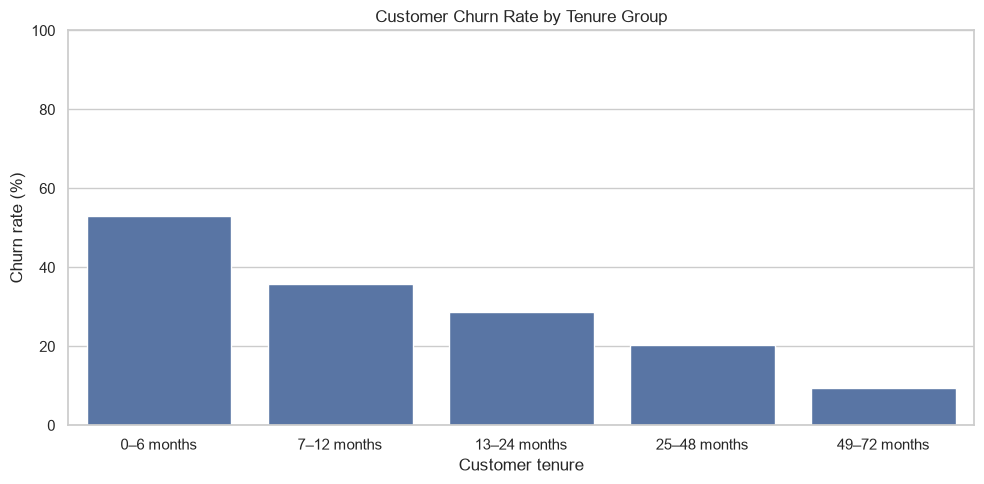

In [124]:
# Group tenure into meaningful ranges
tenure_bins = [-1, 6, 12, 24, 48, 72]
tenure_labels = [
    "0–6 months",
    "7–12 months",
    "13–24 months",
    "25–48 months",
    "49–72 months"
]

telco["TenureBand"] = pd.cut(
    telco["tenure"],
    bins=tenure_bins,
    labels=tenure_labels
)

tenure_summary = (
    telco.groupby("TenureBand", observed=False)
    .agg(
        Customers=("ChurnFlag", "size"),
        Churned=("ChurnFlag", "sum"),
        ChurnRate=("ChurnFlag", "mean")
    )
    .reset_index()
)

tenure_summary["ChurnRate (%)"] = (
    tenure_summary["ChurnRate"] * 100
).round(2)

display(
    tenure_summary[
        ["TenureBand", "Customers", "Churned", "ChurnRate (%)"]
    ]
)

# Plot churn rate by tenure group
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tenure_summary,
    x="TenureBand",
    y="ChurnRate (%)"
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer tenure")
plt.ylabel("Churn rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


Churn summary by Contract:


,Contract,Customers,Churned,ChurnRate (%)
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


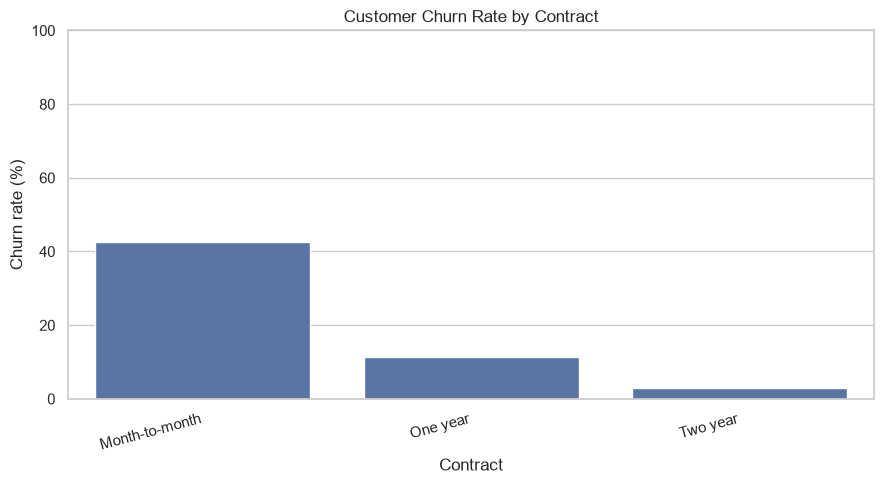


Churn summary by InternetService:


,InternetService,Customers,Churned,ChurnRate (%)
1,Fiber optic,3096,1297,41.89
0,DSL,2421,459,18.96
2,No,1526,113,7.40


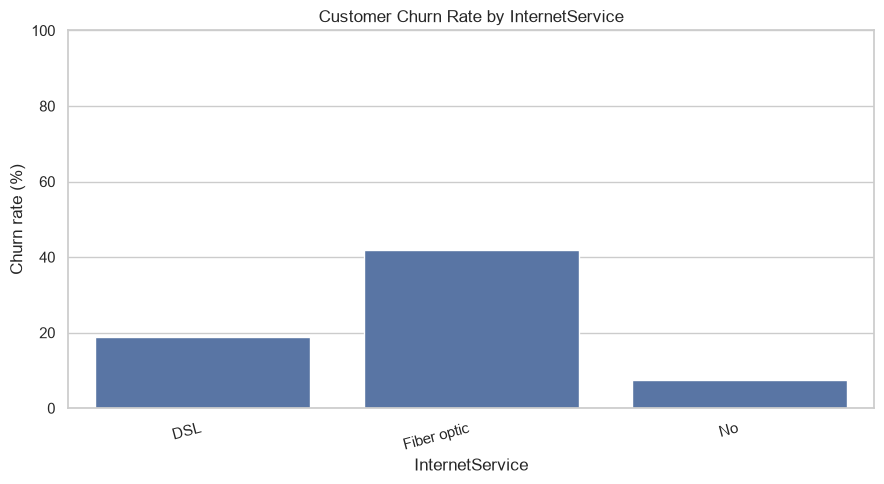

In [125]:
# Calculate churn rates for selected categorical features
features_to_explore = ["Contract", "InternetService"]

for feature in features_to_explore:
    summary = (
        telco.groupby(feature, observed=True)
        .agg(
            Customers=("ChurnFlag", "size"),
            Churned=("ChurnFlag", "sum"),
            ChurnRate=("ChurnFlag", "mean")
        )
        .reset_index()
    )

    summary["ChurnRate (%)"] = (
        summary["ChurnRate"] * 100
    ).round(2)

    print(f"\nChurn summary by {feature}:")
    display(
        summary[
            [feature, "Customers", "Churned", "ChurnRate (%)"]
        ].sort_values("ChurnRate (%)", ascending=False)
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=summary,
        x=feature,
        y="ChurnRate (%)"
    )

    plt.title(f"Customer Churn Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Churn rate (%)")
    plt.ylim(0, 100)
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()

In [126]:
internet_summary = (
    telco.groupby("InternetService", observed=True)
    .agg(
        Customers=("ChurnFlag", "size"),
        Churned=("ChurnFlag", "sum"),
        ChurnRate=("ChurnFlag", "mean")
    )
    .reset_index()
)

internet_summary["ChurnRate (%)"] = (
    internet_summary["ChurnRate"] * 100
).round(2)

display(
    internet_summary[
        ["InternetService", "Customers", "Churned", "ChurnRate (%)"]
    ].sort_values("ChurnRate (%)", ascending=False)
)

,InternetService,Customers,Churned,ChurnRate (%)
1,Fiber optic,3096,1297,41.89
0,DSL,2421,459,18.96
2,No,1526,113,7.40


## 5. Summary of Exploratory Findings

The exploratory analysis identified two prominent patterns in the dataset.

First, churn is associated with customer tenure. The observed churn rate is 52.94% among customers with 0–6 months of tenure, compared with 9.51% among customers with 49–72 months of tenure. This suggests that the early customer relationship is an important area to investigate for retention planning.

Second, churn differs substantially across contract categories. Customers with month-to-month contracts have an observed churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.

The overall churn rate is 26.54%. The early-tenure revenue-weighted churn exposure measure is 61.55%, calculated from the monthly charges associated with churned customers in the 0–6-month group relative to all monthly charges in that group.

These findings are descriptive associations and do not establish causation. Further analysis and predictive modelling are required to assess whether customer characteristics can help identify churn cases on unseen data.

## 6. Feature Selection and Leakage Prevention

The initial predictive task is to classify whether a customer is labelled as churned (`Yes`) or not churned (`No`) using customer and service attributes.

The target variable is `ChurnFlag`, encoded as 1 for churn and 0 for non-churn. The customer identifier, `customerID`, will be excluded because it is an identifier rather than a meaningful behavioural feature.

The generated text fields `PromptInput` and `CustomerFeedback` will also be excluded because they may contain the target label or information derived from it. Using such information could produce misleadingly optimistic evaluation results.

`TotalCharges` will be excluded from the initial model because 11 records contain blank values and the variable is strongly correlated with tenure. The effect of alternative feature choices can be investigated separately if time permits.

The remaining customer and service attributes will form the initial predictor set. Categorical encoding and numerical scaling will be fitted within training pipelines to avoid learning preprocessing parameters from the test set.

Because the data represents a customer snapshot, the resulting models will be evaluated as classifiers on held-out records. Their results alone will not establish prospective performance at a particular point in the customer lifecycle.

In [127]:
# Define the initial feature set
feature_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "MonthlyCharges"
]

target_column = "ChurnFlag"

X = telco[feature_columns].copy()
y = telco[target_column].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFeature columns:")
print(feature_columns)

print("\nTarget distribution:")
display(
    y.value_counts()
    .rename(index={0: "No churn", 1: "Churn"})
    .to_frame("Count")
)

print("\nMissing values in selected features:")
display(
    X.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing values")
)

print("\nTarget missing values:", y.isna().sum())

Feature matrix shape: (7043, 18)
Target vector shape: (7043,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges']

Target distribution:


,Count
ChurnFlag,
No churn,5174
Churn,1869



Missing values in selected features:


,Missing values
gender,0
SeniorCitizen,0
PaymentMethod,0
PaperlessBilling,0
Contract,0
StreamingMovies,0
StreamingTV,0
TechSupport,0
DeviceProtection,0
OnlineBackup,0



Target missing values: 0


In [128]:
numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges"
]

categorical_features = [
    col for col in feature_columns
    if col not in numeric_features
]

print("Number of selected features:", len(feature_columns))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nNumeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

assert len(feature_columns) == 18
assert len(numeric_features) + len(categorical_features) == len(feature_columns)
assert X.isna().sum().sum() == 0
assert y.notna().all()

print("\nFeature and target checks passed.")

Number of selected features: 18
Numeric features: 3
Categorical features: 15

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Feature and target checks passed.


## 7. Train/Test Split and Preprocessing Pipelines

The dataset will be divided into training and test sets using an 80/20 stratified split. Stratification is used because the target classes are imbalanced: approximately 26.54% of customers are labelled as churned.

The training set will be used to fit preprocessing transformations, train the models, and perform cross-validation for hyperparameter selection. The test set will remain separate until the final evaluation to provide a more independent estimate of model performance.

A scikit-learn Pipeline and ColumnTransformer will combine preprocessing with model fitting. Categorical variables will be one-hot encoded, while numerical variables will be standardised for Logistic Regression. Random Forest will use the same one-hot encoding but does not require numerical standardisation.

In [129]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

print("\nChurn proportion:")
split_summary = pd.DataFrame({
    "Full dataset": y.value_counts(normalize=True),
    "Training set": y_train.value_counts(normalize=True),
    "Test set": y_test.value_counts(normalize=True)
}).rename(index={0: "No churn", 1: "Churn"}) * 100

display(split_summary.round(2))

assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))

print("\nTrain/test split checks passed.")

Training features: (5634, 18)
Test features: (1409, 18)
Training target: (5634,)
Test target: (1409,)

Churn proportion:


,Full dataset,Training set,Test set
ChurnFlag,,,
No churn,73.46,73.46,73.46
Churn,26.54,26.54,26.54



Train/test split checks passed.


In [130]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("Scikit-learn pipeline and model imports successful.")

Scikit-learn pipeline and model imports successful.


In [131]:
# Numeric preprocessing for Logistic Regression
numeric_preprocessing_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numeric preprocessing for Random Forest
numeric_preprocessing_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing shared by both models
categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numeric and categorical transformations
preprocessor_lr = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessing_lr, numeric_features),
    ("categorical", categorical_preprocessing, categorical_features)
])

preprocessor_rf = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessing_rf, numeric_features),
    ("categorical", categorical_preprocessing, categorical_features)
])

print("Preprocessing transformers defined successfully.")

Preprocessing transformers defined successfully.


In [132]:
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

print("Logistic Regression pipeline:")
display(logistic_pipeline)

print("\nRandom Forest pipeline:")
display(random_forest_pipeline)

Logistic Regression pipeline:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differen


Random Forest pipeline:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differen

## 8. Baseline Model Training

Two classification algorithms will be compared.

1. **Logistic Regression:** a linear classification model that provides a useful baseline and supports interpretation of relationships between predictors and the log-odds of churn.
2. **Random Forest:** an ensemble of decision trees capable of modelling nonlinear patterns and interactions between customer characteristics.

Both models will use the same training data and the selected predictor set. The preprocessing steps are embedded within each pipeline and will be fitted using the training data only.

These baseline models establish a reference point before cross-validation and hyperparameter tuning. The test set will not be used to select model parameters.

In [133]:
# Fit Logistic Regression
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed.")

# Fit Random Forest
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest training completed.")

Logistic Regression training completed.
Random Forest training completed.


In [134]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

baseline_models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline
}

baseline_results = []

for model_name, model in baseline_models.items():
    # Predicted class labels
    y_pred = model.predict(X_test)

    # Predicted probability for the positive class (Churn = 1)
    y_proba = model.predict_proba(X_test)[:, 1]

    baseline_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

baseline_results_df = pd.DataFrame(baseline_results)

display(
    baseline_results_df
    .set_index("Model")
    .round(4)
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7991,0.6426,0.5481,0.5916,0.8463
Random Forest,0.7807,0.6080,0.4893,0.5422,0.8191



Confusion matrix: Logistic Regression


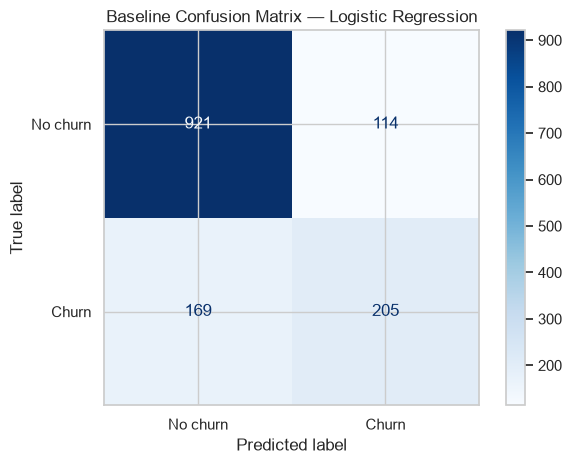


Confusion matrix: Random Forest


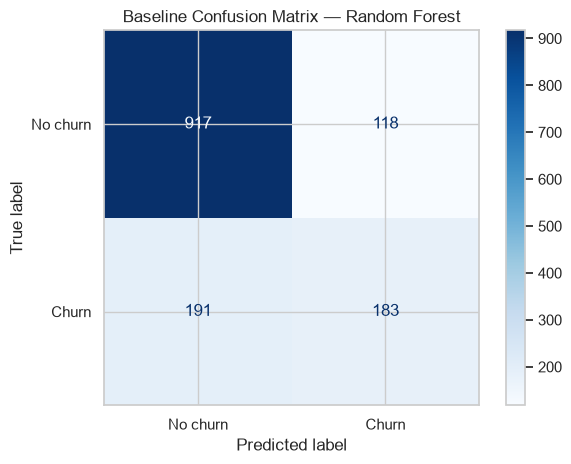

In [135]:
from sklearn.metrics import ConfusionMatrixDisplay

for model_name, model in baseline_models.items():
    print(f"\nConfusion matrix: {model_name}")

    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["No churn", "Churn"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Baseline Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()

## 9. Hyperparameter Tuning and Cross-Validation

The baseline results show that Logistic Regression outperforms Random Forest on the held-out test set across accuracy, precision, recall, F1-score, and ROC-AUC. However, default model settings may not provide the best performance.

Both algorithms will therefore be tuned using five-fold stratified cross-validation on the training set. Stratification preserves the class proportions within each fold.

Grid search will compare predefined hyperparameter combinations. F1-score will be the primary selection metric because it balances precision and recall for the churn class. Recall and ROC-AUC will also be recorded to provide additional perspectives on model performance.

The test set will remain untouched during tuning and will be used only for final evaluation after model selection.

In [136]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring_metrics = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Cross-validation strategy:", cv_strategy)
print("Number of folds:", cv_strategy.get_n_splits())
print("Primary selection metric: F1-score")

Cross-validation strategy: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Number of folds: 5
Primary selection metric: F1-score


In [137]:
lr_param_grid = {
    "classifier__C": [0.1, 1.0, 10.0, 100.0],
    "classifier__class_weight": [None, "balanced"]
}

lr_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=lr_param_grid,
    scoring=scoring_metrics,
    refit="f1",
    cv=cv_strategy,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

lr_search.fit(X_train, y_train)

print("Logistic Regression tuning completed.")
print("Best parameters:", lr_search.best_params_)
print("Best mean cross-validation F1-score:",
      round(lr_search.best_score_, 4))

Logistic Regression tuning completed.
Best parameters: {'classifier__C': 1.0, 'classifier__class_weight': 'balanced'}
Best mean cross-validation F1-score: 0.6274


In [138]:
rf_param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 3],
    "classifier__class_weight": [None, "balanced"]
}

rf_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=rf_param_grid,
    scoring=scoring_metrics,
    refit="f1",
    cv=cv_strategy,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

rf_search.fit(X_train, y_train)

print("Random Forest tuning completed.")
print("Best parameters:", rf_search.best_params_)
print("Best mean cross-validation F1-score:",
      round(rf_search.best_score_, 4))

Random Forest tuning completed.
Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 400}
Best mean cross-validation F1-score: 0.6361


In [139]:
def extract_cv_results(search, model_name):
    results = search.cv_results_
    best_index = search.best_index_

    return {
        "Model": model_name,
        "Best CV Precision": results["mean_test_precision"][best_index],
        "Best CV Recall": results["mean_test_recall"][best_index],
        "Best CV F1-score": results["mean_test_f1"][best_index],
        "Best CV ROC-AUC": results["mean_test_roc_auc"][best_index],
        "F1 CV standard deviation": results["std_test_f1"][best_index]
    }

tuned_cv_results = pd.DataFrame([
    extract_cv_results(lr_search, "Logistic Regression"),
    extract_cv_results(rf_search, "Random Forest")
])

display(
    tuned_cv_results
    .set_index("Model")
    .round(4)
)

,Best CV Precision,Best CV Recall,Best CV F1-score,Best CV ROC-AUC,F1 CV standard deviation
Model,,,,,
Logistic Regression,0.5206,0.7900,0.6274,0.8413,0.0144
Random Forest,0.5610,0.7351,0.6361,0.8390,0.0171


## 10. Final Evaluation of Tuned Models

The best-performing hyperparameter configurations identified through cross-validation are evaluated on the held-out test set. The test set was not used during hyperparameter tuning, providing an independent assessment of model performance.

Accuracy, precision, recall, F1-score and ROC-AUC are reported. As identifying customers who may churn is the business objective, particular attention is given to recall and F1-score, while precision is considered to understand the proportion of predicted churners who actually churned.

Both models use their default classification threshold of 0.5 for the initial comparison. The final model selection will consider predictive performance and the practical implications of false-positive and false-negative predictions.

In [140]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Retrieve the best models selected using cross-validation
best_lr_model = lr_search.best_estimator_
best_rf_model = rf_search.best_estimator_

tuned_models = {
    "Tuned Logistic Regression": best_lr_model,
    "Tuned Random Forest": best_rf_model
}

test_results = []
test_predictions = {}

for model_name, model in tuned_models.items():
    # Predictions at the default threshold of 0.5
    y_pred = model.predict(X_test)

    # Probability estimates for the positive class: Churn = Yes
    y_prob = model.predict_proba(X_test)[:, 1]

    test_predictions[model_name] = y_pred

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_test_results = pd.DataFrame(test_results)

display(
    tuned_test_results
    .set_index("Model")
    .round(4)
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Tuned Logistic Regression,0.7466,0.5145,0.8075,0.6285,0.8461
Tuned Random Forest,0.7665,0.5440,0.7433,0.6282,0.8488


In [141]:
for model_name, model in tuned_models.items():
    y_pred = test_predictions[model_name]
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    print(f"\n{model_name}")
    print("Rows = Actual class; Columns = Predicted class")
    print("Class 0 = No churn; Class 1 = Churn")
    print(cm)

    tn, fp, fn, tp = cm.ravel()

    print(f"True Negatives (TN): {tn}")
    print(f"False Positives (FP): {fp}")
    print(f"False Negatives (FN): {fn}")
    print(f"True Positives (TP): {tp}")


Tuned Logistic Regression
Rows = Actual class; Columns = Predicted class
Class 0 = No churn; Class 1 = Churn
[[750 285]
 [ 72 302]]
True Negatives (TN): 750
False Positives (FP): 285
False Negatives (FN): 72
True Positives (TP): 302

Tuned Random Forest
Rows = Actual class; Columns = Predicted class
Class 0 = No churn; Class 1 = Churn
[[802 233]
 [ 96 278]]
True Negatives (TN): 802
False Positives (FP): 233
False Negatives (FN): 96
True Positives (TP): 278


In [142]:
for model_name, model in tuned_models.items():
    print(f"\n{'=' * 60}")
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            test_predictions[model_name],
            labels=[0, 1],
            target_names=["No Churn", "Churn"],
            digits=4,
            zero_division=0
        )
    )


Tuned Logistic Regression
              precision    recall  f1-score   support

    No Churn     0.9124    0.7246    0.8078      1035
       Churn     0.5145    0.8075    0.6285       374

    accuracy                         0.7466      1409
   macro avg     0.7134    0.7661    0.7181      1409
weighted avg     0.8068    0.7466    0.7602      1409


Tuned Random Forest
              precision    recall  f1-score   support

    No Churn     0.8931    0.7749    0.8298      1035
       Churn     0.5440    0.7433    0.6282       374

    accuracy                         0.7665      1409
   macro avg     0.7186    0.7591    0.7290      1409
weighted avg     0.8004    0.7665    0.7763      1409



## 11. Feature Importance and Business Interpretation

Feature importance is examined to understand which customer attributes contribute most to the selected model's predictive performance. Permutation importance measures the reduction in model performance when the values of an individual feature are randomly shuffled.

The analysis uses ROC-AUC as the scoring metric. Features producing larger decreases in ROC-AUC are considered more influential for the model's ability to distinguish between churners and non-churners.

These results describe predictive importance rather than causal relationships. They do not establish that changing a particular customer attribute will prevent churn.

In [143]:
from sklearn.inspection import permutation_importance

# Explain the tuned Logistic Regression model
# ROC-AUC measures how well the model distinguishes between classes.
permutation_result = permutation_importance(
    estimator=best_lr_model,
    X=X_test,
    y=y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Importance": permutation_result.importances_mean,
    "Standard Deviation": permutation_result.importances_std
}).sort_values(
    "Mean Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

,Feature,Mean Importance,Standard Deviation
0,tenure,0.0877,0.0074
1,InternetService,0.0392,0.0053
2,Contract,0.0332,0.0044
3,MonthlyCharges,0.0190,0.0026
4,StreamingMovies,0.0043,0.0019
5,PaymentMethod,0.0037,0.0008
6,StreamingTV,0.0037,0.0015
7,OnlineSecurity,0.0029,0.0012
8,TechSupport,0.0027,0.0010
9,MultipleLines,0.0027,0.0018


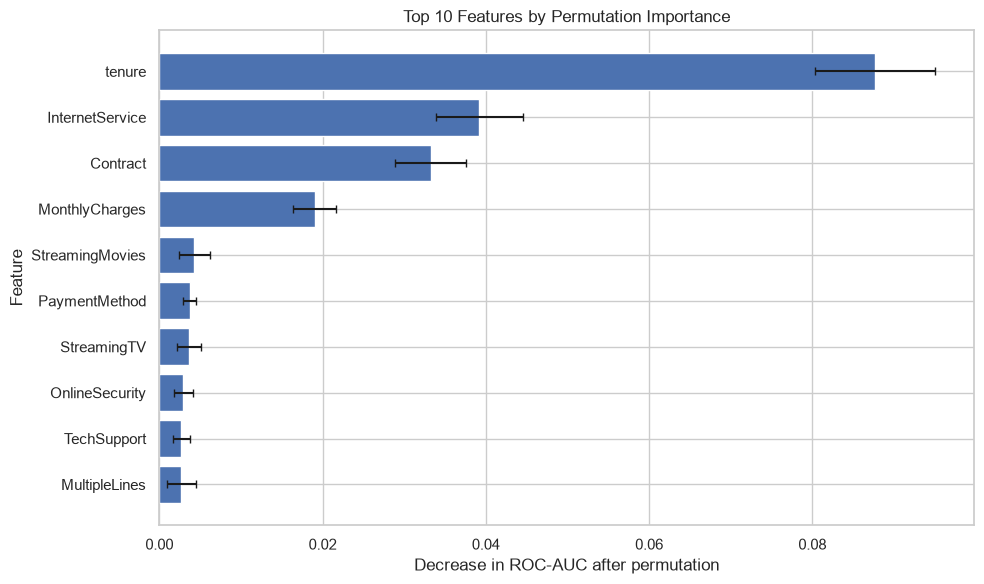

In [144]:
import matplotlib.pyplot as plt

top_features = importance_df.head(10).sort_values(
    "Mean Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Mean Importance"],
    xerr=top_features["Standard Deviation"],
    capsize=3
)

plt.xlabel("Decrease in ROC-AUC after permutation")
plt.ylabel("Feature")
plt.title("Top 10 Features by Permutation Importance")
plt.tight_layout()
plt.show()

In [145]:
# Display the top 10 features as readable text
display(
    importance_df.head(10).round(4)
)

,Feature,Mean Importance,Standard Deviation
0,tenure,0.0877,0.0074
1,InternetService,0.0392,0.0053
2,Contract,0.0332,0.0044
3,MonthlyCharges,0.0190,0.0026
4,StreamingMovies,0.0043,0.0019
5,PaymentMethod,0.0037,0.0008
6,StreamingTV,0.0037,0.0015
7,OnlineSecurity,0.0029,0.0012
8,TechSupport,0.0027,0.0010
9,MultipleLines,0.0027,0.0018


## 12. Key Findings and Business Implications

The permutation importance analysis identified tenure as the most influential feature in the tuned Logistic Regression model, with a mean importance of 0.0877. InternetService (0.0392), Contract (0.0332) and MonthlyCharges (0.0190) were the next most influential features.

These findings are consistent with the exploratory analysis, which showed higher churn rates among customers with shorter tenure, month-to-month contracts and fiber-optic internet service. The results suggest that customer tenure, service type, contract structure and monthly charges may be useful dimensions for investigating churn risk.

The company could consider reviewing the onboarding experience for new customers, evaluating the value offered by different internet packages, communicating the benefits of longer-term contracts and examining whether customer concerns about monthly charges can be addressed.

These actions should be treated as hypotheses for retention experiments rather than guaranteed solutions. The analysis identifies associations in the available dataset and does not establish that changing any individual feature will cause churn to decrease. In addition, permutation importance reflects the predictive contribution of features in this particular model and dataset; it is not a causal ranking.

In [146]:
baseline_comparison = baseline_results_df.copy()
baseline_comparison["Stage"] = "Baseline"

tuned_comparison = tuned_test_results.copy()
tuned_comparison["Stage"] = "Tuned"

tuned_comparison["Model"] = tuned_comparison["Model"].replace({
    "Tuned Logistic Regression": "Logistic Regression",
    "Tuned Random Forest": "Random Forest"
})

comparison_df = pd.concat(
    [baseline_comparison, tuned_comparison],
    ignore_index=True
)

display(
    comparison_df[
        ["Model", "Stage", "Accuracy", "Precision",
         "Recall", "F1-score", "ROC-AUC"]
    ].round(4)
)

,Model,Stage,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,Baseline,0.7991,0.6426,0.5481,0.5916,0.8463
1,Random Forest,Baseline,0.7807,0.6080,0.4893,0.5422,0.8191
2,Logistic Regression,Tuned,0.7466,0.5145,0.8075,0.6285,0.8461
3,Random Forest,Tuned,0.7665,0.5440,0.7433,0.6282,0.8488
